In [1]:
import sys
from contextlib import redirect_stdout
from pathlib import Path
import io

N_JOBS = 2  # Parallel workers per random forest. Use -1 for all available cores.

sys.path.insert(0, str(Path('../..').resolve()))

In [2]:
import pandas as pd

df = pd.read_parquet('../ssi_all_features.parquet')
df.shape

(1636014, 4)

In [3]:
before_delivery_med_features = df.loc[df['description'] == 'before_delivery_medadmin_ingredient', 'feature_name'].unique().tolist()
after_delivery_med_features = df.loc[df['description'] == 'after_delivery_medadmin_ingredient', 'feature_name'].unique().tolist()
or_timings_features = df.loc[df['description'] == 'or_timings', 'feature_name'].unique().tolist()
len(before_delivery_med_features), len(after_delivery_med_features), len(or_timings_features)

(147, 147, 33)

In [4]:
df_pivoted = df.pivot(index='birthid', columns='feature_name', values='feature_value').reset_index()
df_pivoted.columns.name = ''
df_pivoted.shape

(6367, 2024)

In [5]:
from ssi.preprocess import preprocess

buf = io.StringIO()
with redirect_stdout(buf):
    df_pivoted_preprocessed = preprocess(df_pivoted, defer_imputation=True)

/Users/zma/Documents/ammi_wake/ml/python/ssi/preprocess.py:219: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pivoted['parity_isna'] = np.where(df_pivoted['parity'].isna(), 1, 0)
/Users/zma/Documents/ammi_wake/ml/python/ssi/preprocess.py:230: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pivoted[f"{col}_isna"] = df_pivoted[col].isna().astype(float)
/Users/zma/Documents/ammi_wake/ml/python/ssi/preprocess.py:230: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many ti

In [6]:
df_pivoted_preprocessed.isna().sum().sort_values(ascending=False)

preexisting_diabetes_cmqcc_category_count                                                     6258
preexisting_hypertension_cmqcc_category_count                                                 6204
chorioamnionitis_cmqcc_category_count                                                         6172
preeclampsia_cmqcc_category_count                                                             6095
premature_rupture_of_membranes_cmqcc_category_count                                           5965
                                                                                              ... 
114202+1901+8591+9863_INTRAVENOUS_after_delivery_medadmin_ingredient_dose_missing_fraction       0
114202+1901+8591+9863_INTRAVENOUS_after_delivery_medadmin_ingredient_earliest_minute             0
114202+1901+8591+9863_INTRAVENOUS_after_delivery_medadmin_ingredient_latest_minute               0
114202+1901+8591+9863_INTRAVENOUS_after_delivery_medadmin_ingredient_total_count                 0
105202_INT

In [7]:
from ssi.feature_filter import feature_filter

excluded = {'birthid', 'mother_patid', 'target_variable'}
X = df_pivoted_preprocessed.drop(columns=list(excluded))
y = df_pivoted_preprocessed['target_variable']
mother_patid = df_pivoted_preprocessed['mother_patid']

# Inspect the predefined schema and retain observed values for descriptive plots.
# Model pipelines apply the same filter to their own input.
with redirect_stdout(io.StringIO()):
    df_pivoted_filtered = feature_filter(X.copy(), skip_medadmin_ingredient=True)

In [8]:
# Run through this cell for the feature list alone. The cells below fit models.
feature_names = df_pivoted_filtered.columns.tolist()
if not feature_names or len(feature_names) != len(set(feature_names)):
    raise ValueError('Expected a nonempty list of unique predictor names.')
inventory_path = Path('results/feature_inventory/ssi_available_feature_columns.txt')
inventory_path.parent.mkdir(parents=True, exist_ok=True)
inventory_path.write_text('\n'.join(feature_names) + '\n', encoding='utf-8')
print(f'Wrote {len(feature_names)} predictor names to {inventory_path}')

Wrote 1266 predictor names to results/feature_inventory/ssi_available_feature_columns.txt


In [9]:
before_delivery_med_features = [x for x in before_delivery_med_features if x in df_pivoted_filtered.columns]
after_delivery_med_features = [x for x in after_delivery_med_features if x in df_pivoted_filtered.columns]
or_timings_features = [x for x in df_pivoted_filtered.columns if x.startswith('or_timings')]
len(before_delivery_med_features), len(after_delivery_med_features), len(or_timings_features)

(147, 147, 66)

In [10]:
med_features = [x for x in df_pivoted_filtered.columns if 'medadmin_ingredient' in x]
len(med_features)  # this has more since it has _isna features in it

336

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from src.clinical_imputer import ClinicalImputer
from src.model_training import nested_cv_evaluation_feature_selection

param_grid = {'clf__min_samples_split': [20, 50, 70, 100, 200, 500]}
cv_settings = dict(groups=mother_patid, outer_splits=5, inner_splits=5, random_state=range(10))

def rf_pipeline(columns):
    return Pipeline([
        ('clinical', ClinicalImputer(columns=columns)),
        ('clf', RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=N_JOBS)),
    ])

### 1 pcornet features only

In [12]:
pcornet_features = [x for x in df_pivoted_filtered.columns if x not in or_timings_features]
len(pcornet_features)

1200

In [13]:
model_features = pcornet_features
print(f'Predictors: {len(model_features)}') 
metrics_baseline = nested_cv_evaluation_feature_selection(
    X, y, rf_pipeline(model_features), param_grid, **cv_settings,
)

Predictors: 1200
start inner cv
[Repeat 0, fold 1] ROC-AUC=0.6324, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 0, fold 2] ROC-AUC=0.6069, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 0, fold 3] ROC-AUC=0.6037, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 0, fold 4] ROC-AUC=0.6147, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 0, fold 5] ROC-AUC=0.5900, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 1] ROC-AUC=0.5997, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 1, fold 2] ROC-AUC=0.6115, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 3] ROC-AUC=0.5821, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 4] ROC-AUC=0.6256, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 5] ROC-AUC=0.5193, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 2, fold 1] ROC-AUC=0.5

In [14]:
metrics_baseline

,repeat,outer_fold,f1,roc_auc,ap,best_params,sens_50,sens_80,sens_90
0,0,1,0.000000,0.632354,0.063312,{'clf__min_samples_split': 100},0.051522,0.043286,0.039695
1,0,2,0.031746,0.606937,0.050435,{'clf__min_samples_split': 100},0.047304,0.036815,0.036485
2,0,3,0.000000,0.603687,0.068027,{'clf__min_samples_split': 100},0.037620,0.040028,0.036382
3,0,4,0.080000,0.614672,0.045996,{'clf__min_samples_split': 500},0.050057,0.043467,0.038634
4,0,5,0.083916,0.589998,0.068840,{'clf__min_samples_split': 200},0.044744,0.034420,0.036111
5,1,1,0.000000,0.599739,0.053618,{'clf__min_samples_split': 70},0.050291,0.040739,0.037438
6,1,2,0.092664,0.611475,0.053030,{'clf__min_samples_split': 500},0.066465,0.036132,0.035882
7,1,3,0.137931,0.582095,0.063225,{'clf__min_samples_split': 200},0.036720,0.040121,0.039221
8,1,4,0.100000,0.625581,0.063621,{'clf__min_samples_split': 200},0.046586,0.041828,0.042448
9,1,5,0.038462,0.519266,0.038509,{'clf__min_samples_split': 70},0.036533,0.034909,0.033399


In [15]:
import shap

def get_shap(clf, X, max_display=30):
    explainer = shap.TreeExplainer(clf, data=X,
                                   model_output='probability', feature_perturbation='interventional')
    shap_values = explainer(X, check_additivity=True)
    shap_values.values = shap_values.values[:,:,1]
    shap.plots.beeswarm(shap_values, max_display=max_display)
    return shap_values

/opt/anaconda3/envs/ammi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fontconfig warning: ignoring UTF-8: not a valid region tag
Matplotlib is building the font cache; this may take a moment.


100%|===================| 12721/12734 [04:00<00:00]        

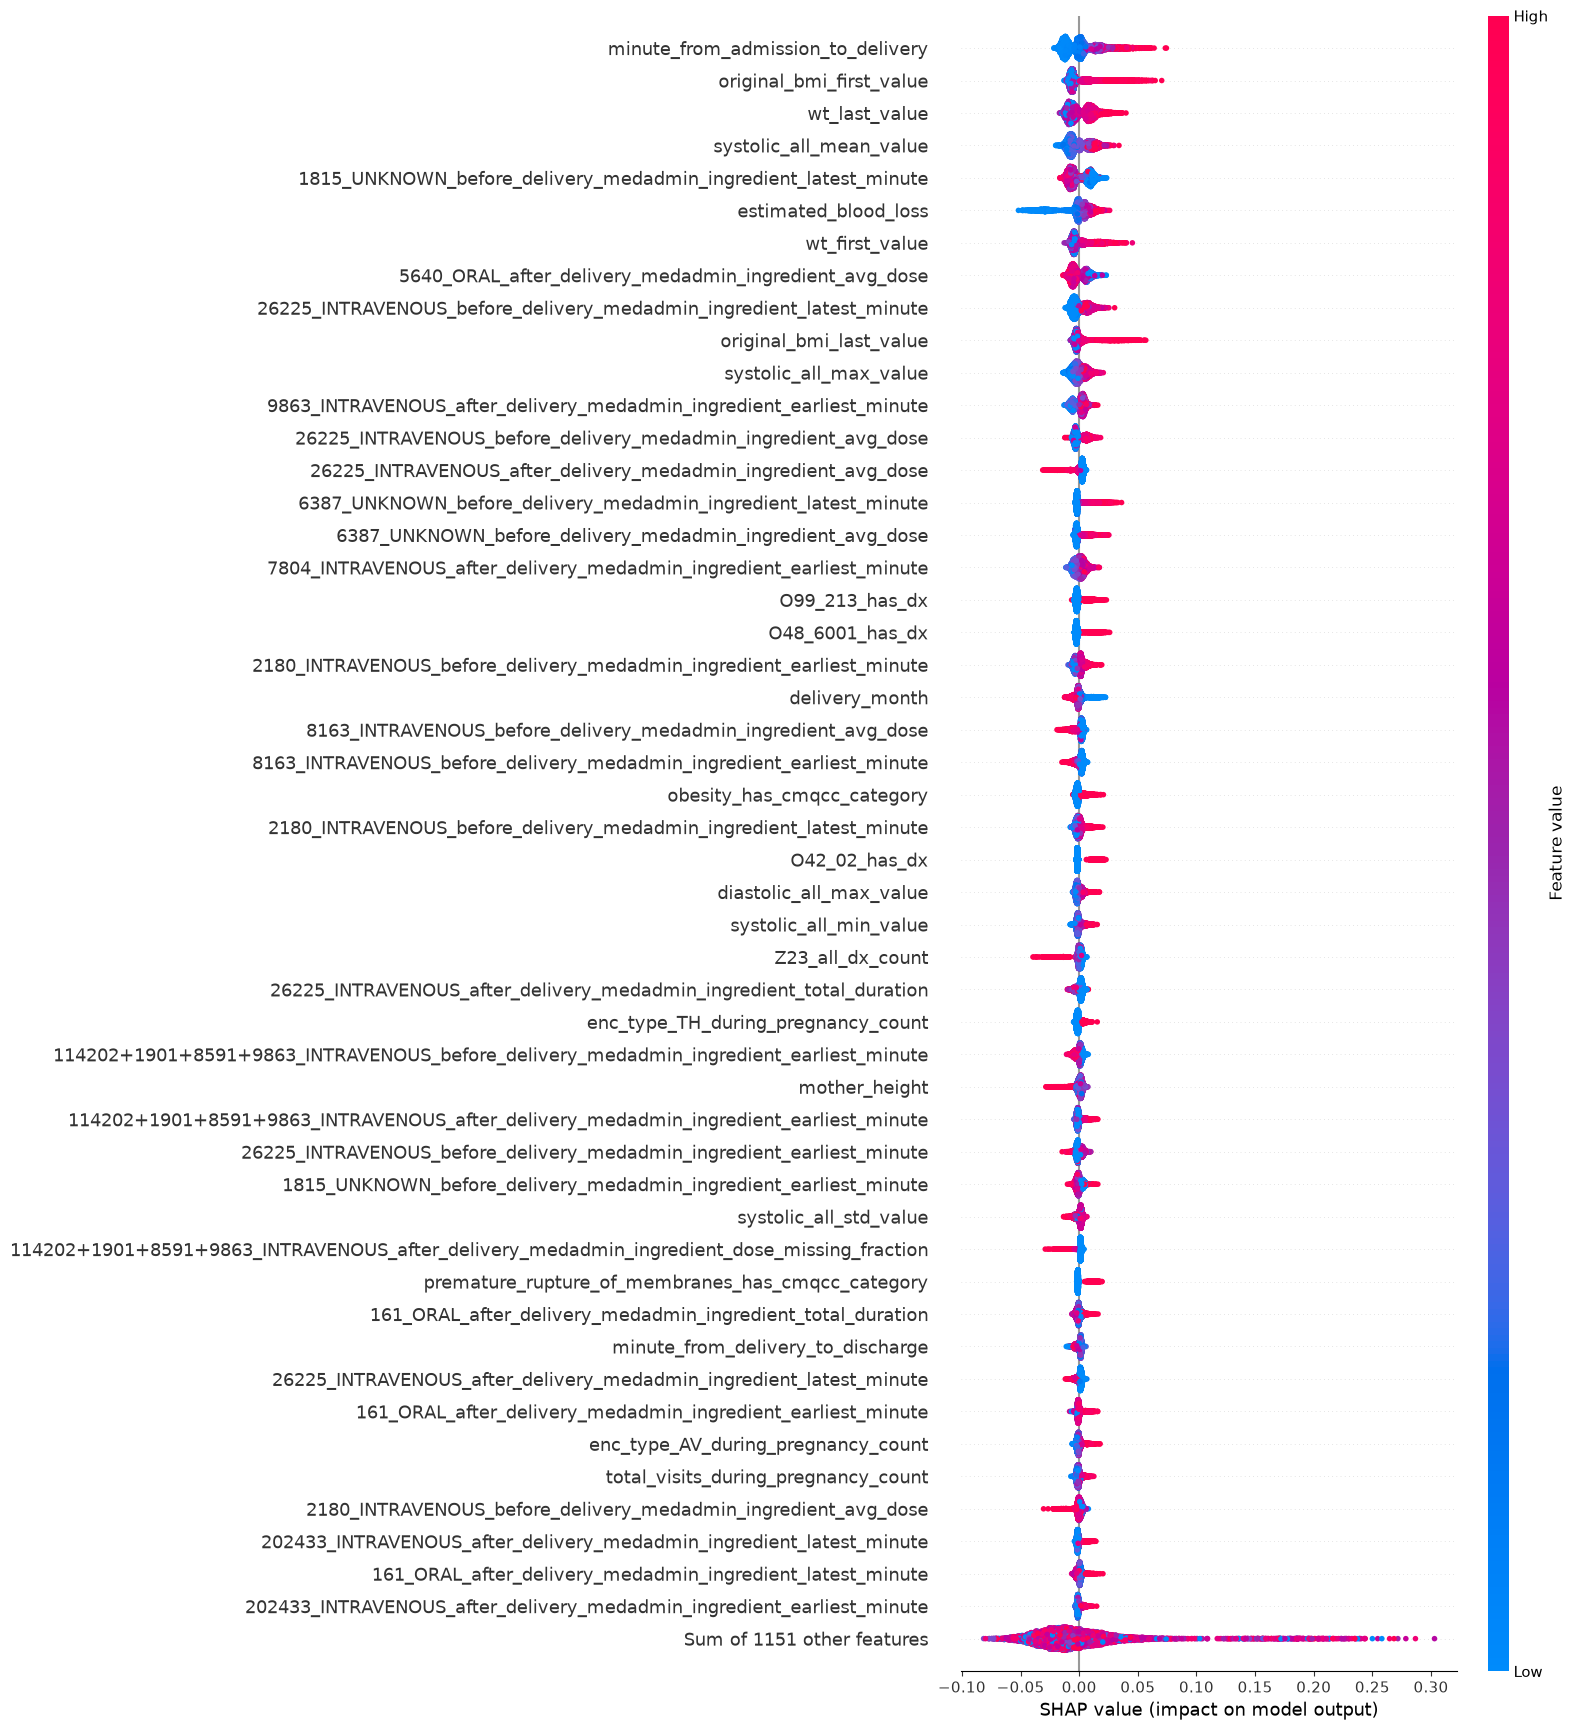

In [16]:
clf = rf_pipeline(model_features).set_params(clf__min_samples_split=100)
clf.fit(X, y)
shap_values = get_shap(clf.named_steps['clf'], clf[:-1].transform(X), max_display=50)

### 2. med features only using start time

In [17]:
pcornet_features_subset = []
for x in pcornet_features:
    if x in med_features:
        if 'has_medadmin_ingredient' in x:
            pcornet_features_subset.append(x)
        if x.endswith('earliest_minute'):
            pcornet_features_subset.append(x)
    else:
        pcornet_features_subset.append(x)

In [18]:
model_features = pcornet_features_subset
print(f'Predictors: {len(model_features)}')
metrics_2 = nested_cv_evaluation_feature_selection(
    X, y, rf_pipeline(model_features), param_grid, **cv_settings,
)

Predictors: 948
start inner cv
[Repeat 0, fold 1] ROC-AUC=0.5702, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 0, fold 2] ROC-AUC=0.5926, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 0, fold 3] ROC-AUC=0.5594, best_params={'clf__min_samples_split': 50}
start inner cv
[Repeat 0, fold 4] ROC-AUC=0.5937, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 0, fold 5] ROC-AUC=0.6119, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 1] ROC-AUC=0.6128, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 2] ROC-AUC=0.6143, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 3] ROC-AUC=0.5782, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 1, fold 4] ROC-AUC=0.6488, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 1, fold 5] ROC-AUC=0.5289, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 2, fold 1] ROC-AUC=0.57

100%|===================| 12722/12734 [04:21<00:00]        

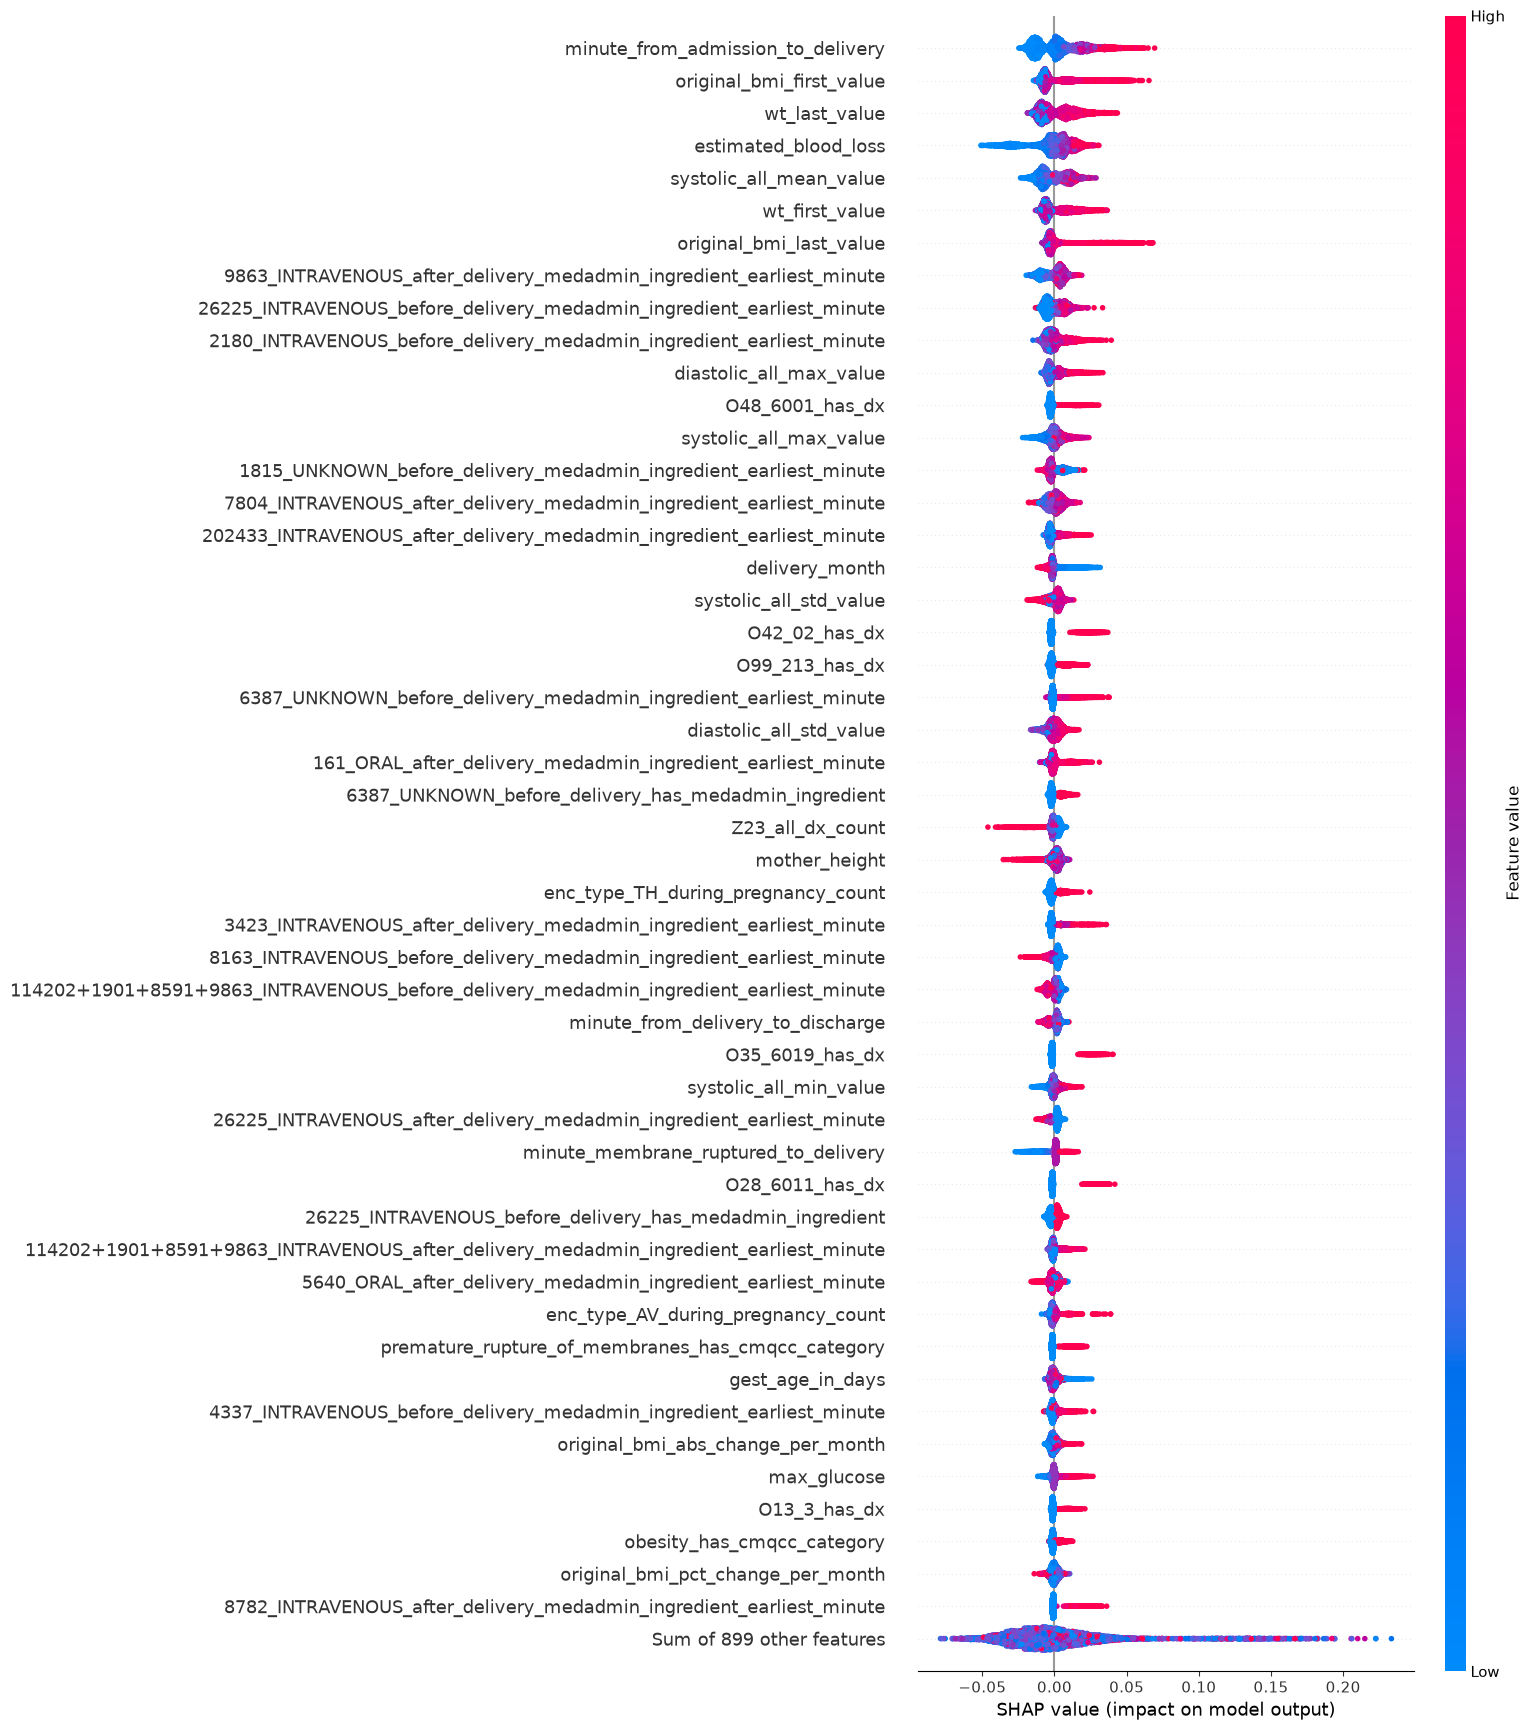

In [19]:
clf = rf_pipeline(model_features).set_params(clf__min_samples_split=100)
clf.fit(X, y)
shap_values = get_shap(clf.named_steps['clf'], clf[:-1].transform(X), max_display=50)

### 3. pcornet subset without start time and or timings

In [20]:
pcornet_features_subset = []
for x in pcornet_features:
    if x in med_features:
        if 'has_medadmin_ingredient' in x:
            pcornet_features_subset.append(x)
    else:
        pcornet_features_subset.append(x)
print(len(pcornet_features_subset))

906


In [21]:
model_features = pcornet_features_subset + or_timings_features
print(f'Predictors: {len(model_features)}')
metrics_3 = nested_cv_evaluation_feature_selection(
    X, y, rf_pipeline(model_features), param_grid, **cv_settings,
)

Predictors: 972
start inner cv
[Repeat 0, fold 1] ROC-AUC=0.6150, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 0, fold 2] ROC-AUC=0.6166, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 0, fold 3] ROC-AUC=0.6206, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 0, fold 4] ROC-AUC=0.6359, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 0, fold 5] ROC-AUC=0.6242, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 1] ROC-AUC=0.6071, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 2] ROC-AUC=0.6624, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 1, fold 3] ROC-AUC=0.6068, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 4] ROC-AUC=0.7080, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 5] ROC-AUC=0.5649, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 2, fold 1] ROC-AUC=0.625

100%|===================| 12732/12734 [04:36<00:00]        

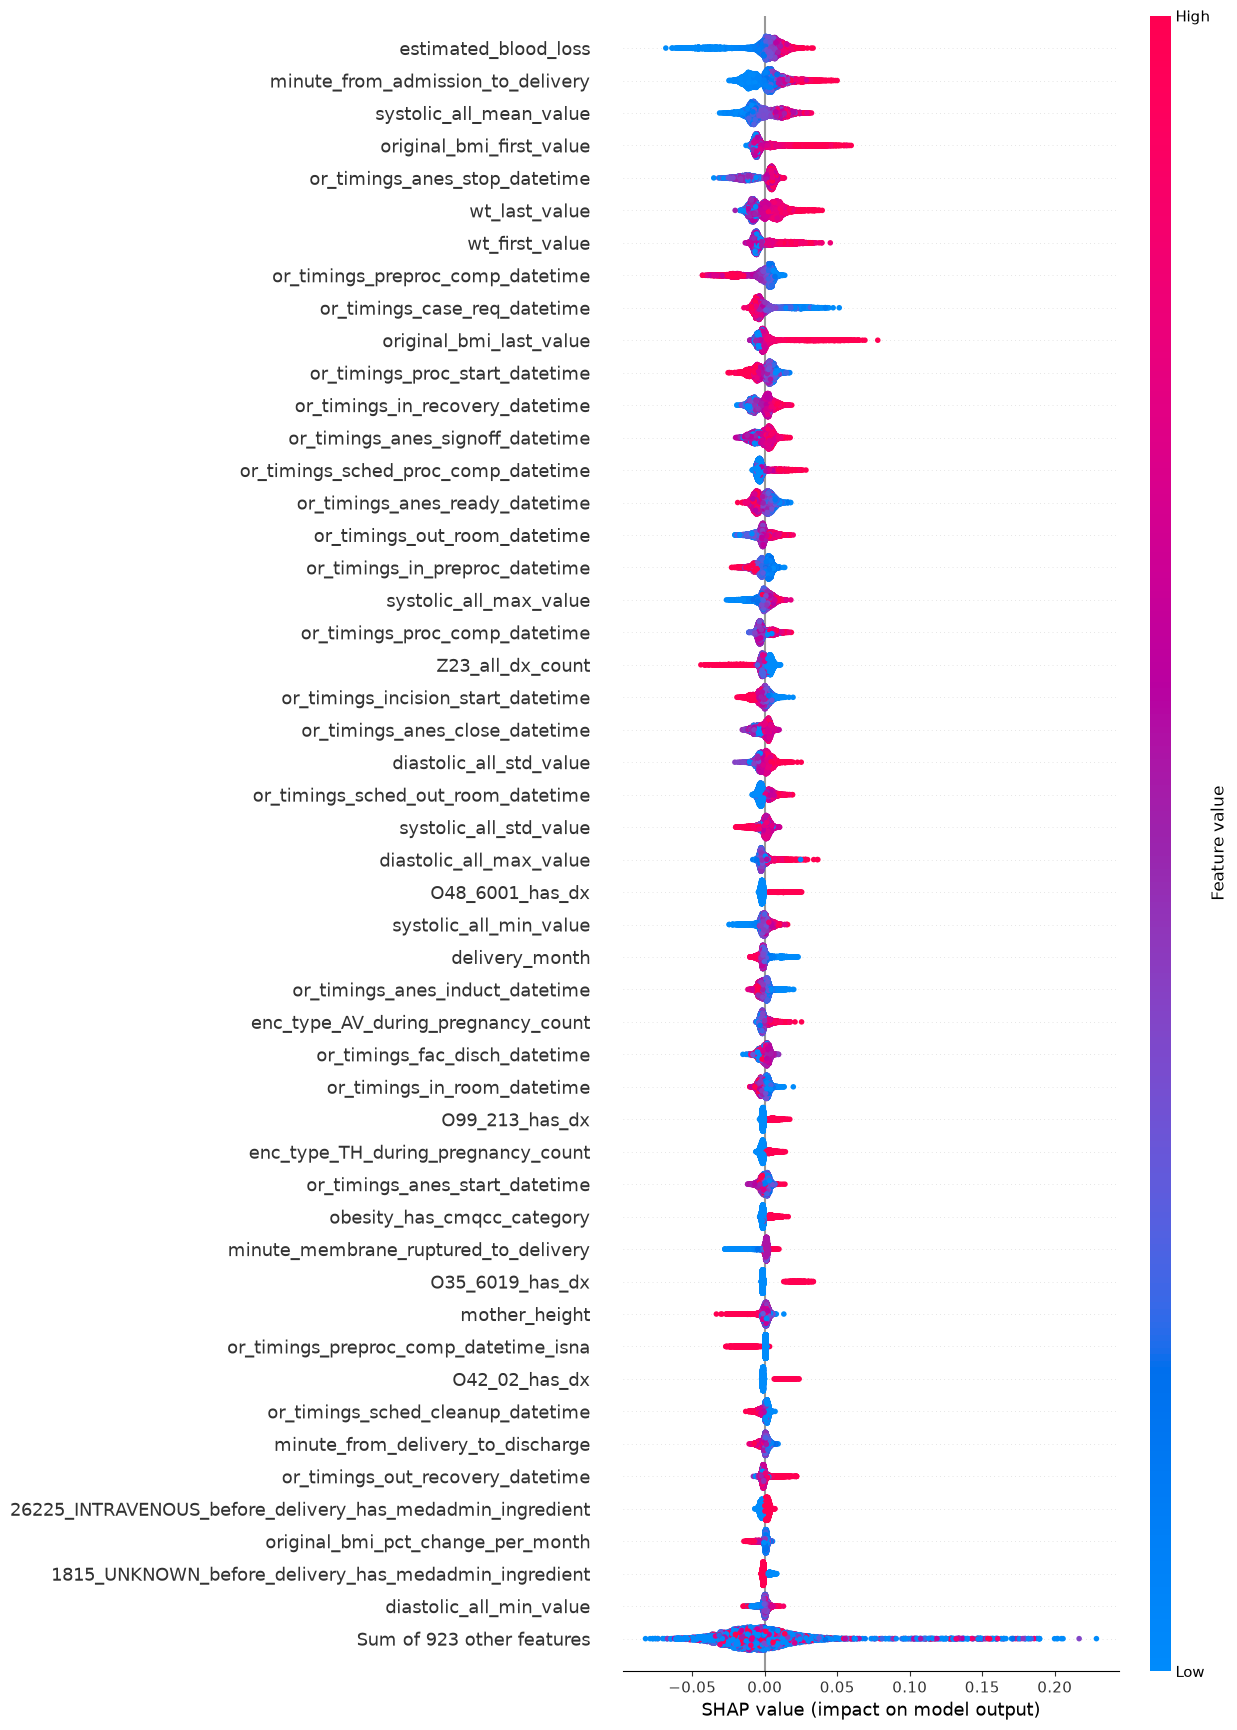

In [22]:
clf = rf_pipeline(model_features).set_params(clf__min_samples_split=100)
clf.fit(X, y)
shap_values = get_shap(clf.named_steps['clf'], clf[:-1].transform(X), max_display=50)

In [23]:
metrics_baseline['test'] = 'pcornet everything'
metrics_2['test'] = 'pcornet_has_med + med_earliest_minute'
metrics_3['test'] = 'pcornet_has_med + or_timings'
all_metrics = pd.concat([metrics_baseline, metrics_2, metrics_3], axis=0)
all_metrics

,repeat,outer_fold,f1,roc_auc,ap,best_params,sens_50,sens_80,sens_90,test
0,0,1,0.000000,0.632354,0.063312,{'clf__min_samples_split': 100},0.051522,0.043286,0.039695,pcornet everything
1,0,2,0.031746,0.606937,0.050435,{'clf__min_samples_split': 100},0.047304,0.036815,0.036485,pcornet everything
2,0,3,0.000000,0.603687,0.068027,{'clf__min_samples_split': 100},0.037620,0.040028,0.036382,pcornet everything
3,0,4,0.080000,0.614672,0.045996,{'clf__min_samples_split': 500},0.050057,0.043467,0.038634,pcornet everything
4,0,5,0.083916,0.589998,0.068840,{'clf__min_samples_split': 200},0.044744,0.034420,0.036111,pcornet everything
...,...,...,...,...,...,...,...,...,...,...
45,9,1,0.093458,0.565205,0.065174,{'clf__min_samples_split': 200},0.034482,0.036658,0.036212,pcornet_has_med + or_timings
46,9,2,0.110000,0.648119,0.058792,{'clf__min_samples_split': 500},0.060991,0.040739,0.041671,pcornet_has_med + or_timings
47,9,3,0.024096,0.634146,0.061646,{'clf__min_samples_split': 100},0.048998,0.041256,0.039262,pcornet_has_med + or_timings
48,9,4,0.075829,0.617829,0.064124,{'clf__min_samples_split': 200},0.048918,0.040835,0.040367,pcornet_has_med + or_timings


(0.6, 0.75)

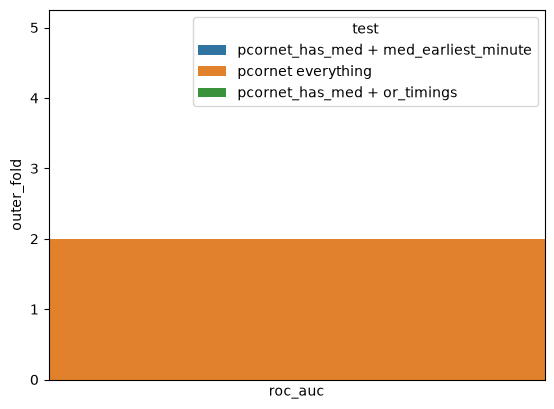

In [24]:
import seaborn as sns
from matplotlib import pyplot as plt

sns.barplot(all_metrics, y='outer_fold', x='roc_auc', hue='test', errorbar=None)
plt.xlim([0.6, 0.75])

(0.6, 0.72)

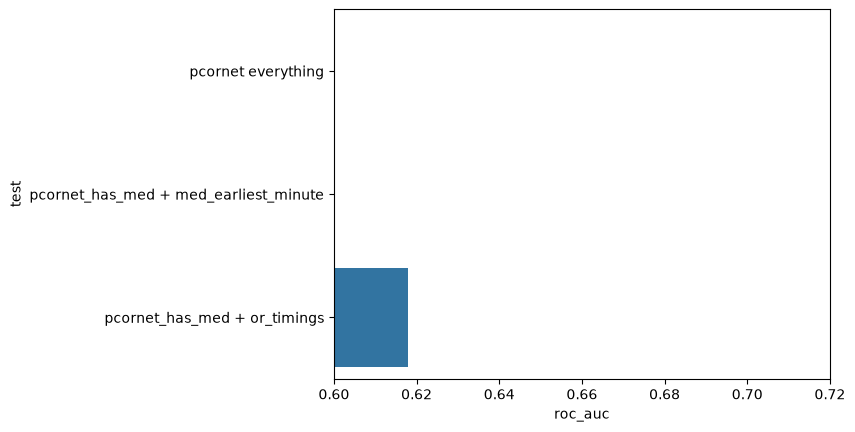

In [25]:
sns.barplot(all_metrics, x='roc_auc', y='test', errorbar=None)
plt.xlim([0.60, 0.72])

### 4 only has med???

In [26]:
pcornet_features_subset = []
for x in pcornet_features:
    if x in med_features:
        if 'has_medadmin_ingredient' in x:
            pcornet_features_subset.append(x)
    else:
        pcornet_features_subset.append(x)


model_features = pcornet_features_subset
print(f'Predictors: {len(model_features)}')
metrics_4 = nested_cv_evaluation_feature_selection(
    X, y, rf_pipeline(model_features), param_grid, **cv_settings,
)

Predictors: 906
start inner cv
[Repeat 0, fold 1] ROC-AUC=0.5991, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 0, fold 2] ROC-AUC=0.5831, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 0, fold 3] ROC-AUC=0.6381, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 0, fold 4] ROC-AUC=0.6094, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 0, fold 5] ROC-AUC=0.6121, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 1] ROC-AUC=0.6346, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 1, fold 2] ROC-AUC=0.6211, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 3] ROC-AUC=0.5858, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 1, fold 4] ROC-AUC=0.6668, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 5] ROC-AUC=0.5420, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 2, fold 1] ROC-AUC=0.598

(0.6, 0.72)

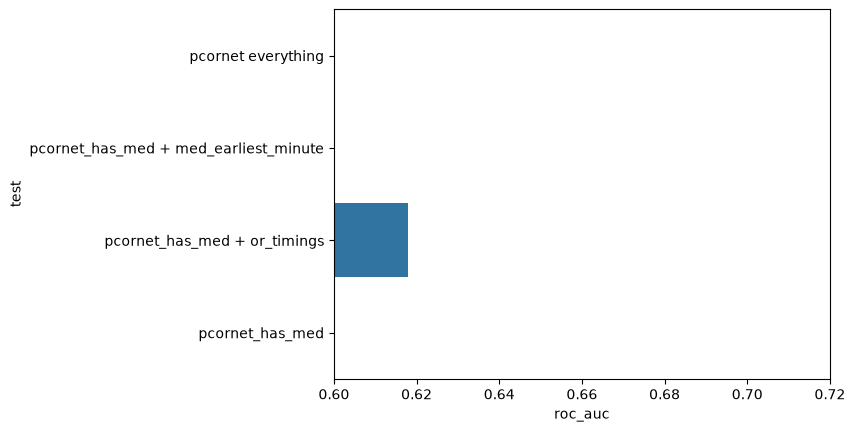

In [27]:
metrics_baseline['test'] = 'pcornet everything'
metrics_2['test'] = 'pcornet_has_med + med_earliest_minute'
metrics_3['test'] = 'pcornet_has_med + or_timings'
metrics_4['test'] = 'pcornet_has_med'
all_metrics = pd.concat([metrics_baseline, metrics_2, metrics_3, metrics_4], axis=0)

sns.barplot(all_metrics, x='roc_auc', y='test', errorbar=None)
plt.xlim([0.60, 0.72])

### 5, earliest + or timings

In [28]:
pcornet_features_subset = []
for x in pcornet_features:
    if x in med_features:
        if 'has_medadmin_ingredient' in x:
            pcornet_features_subset.append(x)
        if x.endswith('earliest_minute'):
            pcornet_features_subset.append(x)
    else:
        pcornet_features_subset.append(x)


model_features = pcornet_features_subset + or_timings_features
print(f'Predictors: {len(model_features)}')
metrics_5 = nested_cv_evaluation_feature_selection(
    X, y, rf_pipeline(model_features), param_grid, **cv_settings,
)

Predictors: 1014
start inner cv
[Repeat 0, fold 1] ROC-AUC=0.6252, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 0, fold 2] ROC-AUC=0.6074, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 0, fold 3] ROC-AUC=0.6186, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 0, fold 4] ROC-AUC=0.6455, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 0, fold 5] ROC-AUC=0.6154, best_params={'clf__min_samples_split': 100}
start inner cv
[Repeat 1, fold 1] ROC-AUC=0.6058, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 2] ROC-AUC=0.6554, best_params={'clf__min_samples_split': 500}
start inner cv
[Repeat 1, fold 3] ROC-AUC=0.5997, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 4] ROC-AUC=0.6887, best_params={'clf__min_samples_split': 200}
start inner cv
[Repeat 1, fold 5] ROC-AUC=0.5461, best_params={'clf__min_samples_split': 70}
start inner cv
[Repeat 2, fold 1] ROC-AUC=0.6

(0.6, 0.72)

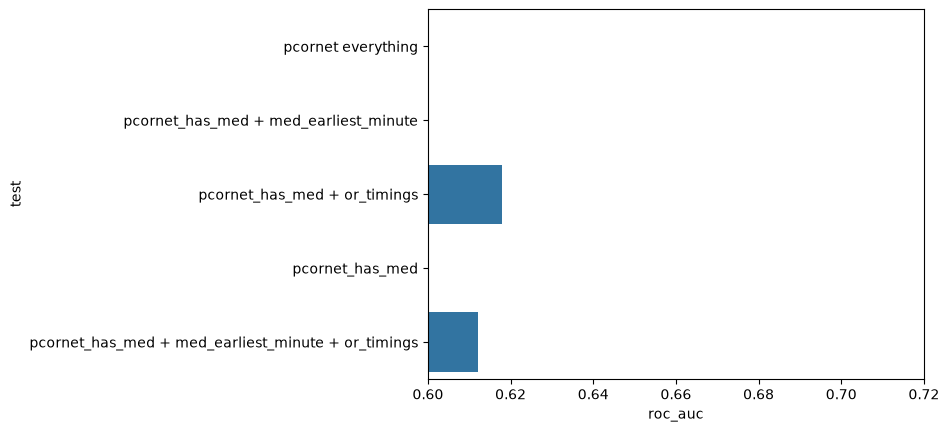

In [29]:
metrics_baseline['test'] = 'pcornet everything'
metrics_2['test'] = 'pcornet_has_med + med_earliest_minute'
metrics_3['test'] = 'pcornet_has_med + or_timings'
metrics_4['test'] = 'pcornet_has_med'
metrics_5['test'] = 'pcornet_has_med + med_earliest_minute + or_timings'
all_metrics = pd.concat([metrics_baseline, metrics_2, metrics_3, metrics_4, metrics_5], axis=0)

sns.barplot(all_metrics, x='roc_auc', y='test', errorbar=None)
plt.xlim([0.60, 0.72])

100%|===================| 12712/12734 [04:21<00:00]        

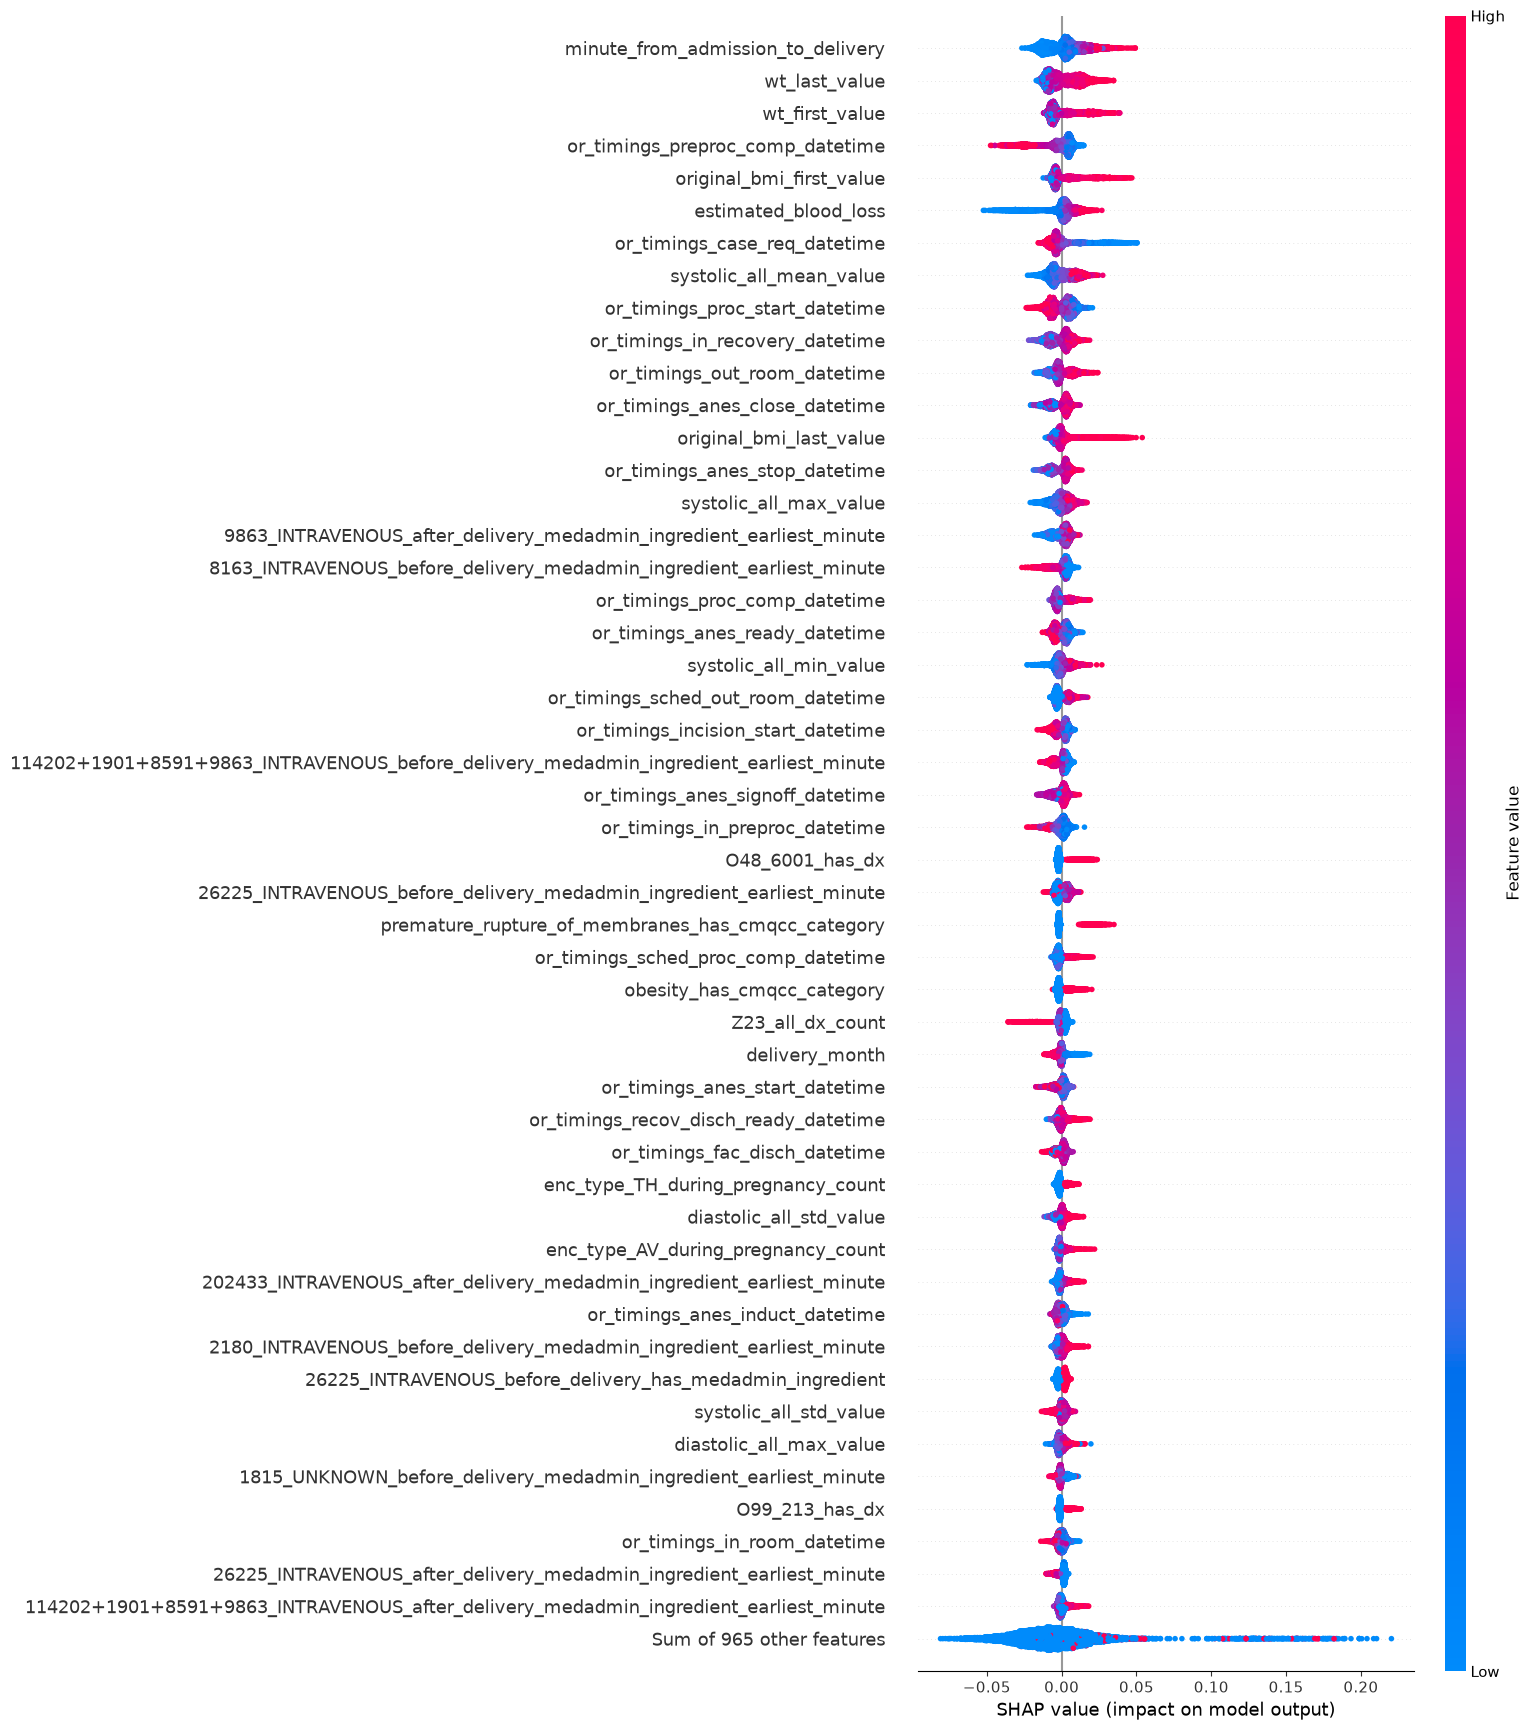

In [30]:
clf = rf_pipeline(model_features).set_params(clf__min_samples_split=100)
clf.fit(X, y)
shap_values = get_shap(clf.named_steps['clf'], clf[:-1].transform(X), max_display=50)

In [31]:
results_dir = Path('results/timing_revision')
results_dir.mkdir(parents=True, exist_ok=True)
all_metrics.to_csv(results_dir / 'outer_fold_metrics.csv', index=False)

In [32]:
# Submitted Table 2 values are rounded. Changes from submission are descriptive.
submitted_auc = pd.Series({
    'pcornet_has_med': 0.677,
    'pcornet_has_med + or_timings': 0.692,
    'pcornet_has_med + med_earliest_minute': 0.693,
    'pcornet_has_med + med_earliest_minute + or_timings': 0.701,
}, name='submitted_roc_auc')
summary = all_metrics.groupby('test')[['roc_auc', 'ap', 'sens_80']].mean()
summary = summary.loc[submitted_auc.index].join(submitted_auc)
summary['roc_auc_change_from_submission'] = summary['roc_auc'] - summary['submitted_roc_auc']
summary.to_csv(results_dir / 'performance_summary.csv')
summary

,roc_auc,ap,sens_80,submitted_roc_auc,roc_auc_change_from_submission
test,,,,,
pcornet_has_med,0.598809,0.060105,0.039632,0.677,-0.078191
pcornet_has_med + or_timings,0.617835,0.060708,0.040807,0.692,-0.074165
pcornet_has_med + med_earliest_minute,0.596657,0.059364,0.039379,0.693,-0.096343
pcornet_has_med + med_earliest_minute + or_timings,0.612117,0.059049,0.040835,0.701,-0.088883


In [33]:
# Pair the corrected results by repeat and outer fold. Folds reuse patients.
matched = all_metrics.pivot(index=['repeat', 'outer_fold'], columns='test', values='roc_auc')
if matched.isna().any().any():
    raise ValueError('Missing matched outer-fold ROC-AUC results.')
paired_deltas = matched[submitted_auc.index[1:]].subtract(matched['pcornet_has_med'], axis=0)
paired_deltas.to_csv(results_dir / 'paired_roc_auc_differences.csv')
paired_deltas.agg(['mean', 'std'])

test,pcornet_has_med + or_timings,pcornet_has_med + med_earliest_minute,pcornet_has_med + med_earliest_minute + or_timings
mean,0.019026,-0.002152,0.013308
std,0.025741,0.019456,0.029833


### 6 figure out the interpretation

In [34]:
def return_null_col(df, col):
    values = df[col]
    if 'medadmin_ingredient' in col:
        prefix = col.split('_medadmin_ingredient')[0]
        return values.where(df[f'{prefix}_has_medadmin_ingredient'].eq(1))
    return values.where(df[f'{col}_isna'].eq(0))

In [35]:
import numpy as np

df_or_timings = df_pivoted_filtered[or_timings_features].copy()
cols_to_drop = []
for x in or_timings_features:
    if x.endswith('_isna') or f'{x}_isna' not in df_or_timings:  continue
    df_or_timings[x] = return_null_col(df_or_timings, x)
    cols_to_drop.append(f"{x}_isna")
df_or_timings = df_or_timings.drop(columns=cols_to_drop)
df_or_timings.mean()

or_timings_anes_addend_datetime             1057.979798
or_timings_anes_close_datetime                81.514413
or_timings_anes_emerge_datetime               51.147692
or_timings_anes_epidural_datetime            -56.410092
or_timings_anes_induct_datetime              -32.364218
or_timings_anes_ready_datetime               -25.138341
or_timings_anes_signoff_datetime              96.349350
or_timings_anes_start_datetime               -39.959512
or_timings_anes_stop_datetime                 65.448575
or_timings_case_req_datetime               -1174.492617
or_timings_extubation_datetime                55.332288
or_timings_fac_disch_datetime               4542.527955
or_timings_in_phase_ii_datetime              151.071845
or_timings_in_preproc_datetime               -70.346757
or_timings_in_recovery_datetime               61.378402
or_timings_in_room_datetime                  -35.394391
or_timings_incision_start_datetime           -21.076021
or_timings_intubation_datetime               -31

In [36]:
col = '1815_UNKNOWN_before_delivery_medadmin_ingredient_earliest_minute'
val = return_null_col(df_pivoted_filtered, col)
(
    df_or_timings.corrwith(val, method='spearman')
                 .sort_values()
)

or_timings_service_start_datetime          -0.702360
or_timings_anes_start_datetime             -0.701524
or_timings_sched_setup_datetime            -0.659114
or_timings_anes_induct_datetime            -0.651615
or_timings_in_preproc_datetime             -0.647865
or_timings_preproc_comp_datetime           -0.646716
or_timings_in_room_datetime                -0.645232
or_timings_sched_in_room_datetime          -0.642696
or_timings_intubation_datetime             -0.632032
or_timings_sched_proc_start_datetime       -0.623520
or_timings_anes_ready_datetime             -0.603963
or_timings_incision_start_datetime         -0.601025
or_timings_proc_start_datetime             -0.600859
or_timings_anes_epidural_datetime          -0.550242
or_timings_case_req_datetime               -0.168840
or_timings_phase_ii_disch_ready_datetime   -0.003294
or_timings_anes_addend_datetime             0.007813
or_timings_extubation_datetime              0.021155
or_timings_recov_disch_ready_datetime       0.

In [ ]:
import seaborn as sns
from matplotlib import pyplot as plt

tmp = pd.concat([-df_or_timings['or_timings_anes_start_datetime'], val], axis=1)

sns.scatterplot(tmp, x='or_timings_anes_start_datetime', y=col)
plt.xlim([-100, 3000])
plt.ylim([-100, 3000])
plt.xlabel("Anesthesia Start Time (minutes before delivery)")
plt.ylabel("Earliest time of bupivacaine (minutes before delivery)")
plt.savefig(results_dir / 'figure_5.png', bbox_inches='tight', dpi=200)

### 7. remake some plots for the main result

In [38]:
all_metrics

,repeat,outer_fold,f1,roc_auc,ap,best_params,sens_50,sens_80,sens_90,test
0,0,1,0.000000,0.632354,0.063312,{'clf__min_samples_split': 100},0.051522,0.043286,0.039695,pcornet everything
1,0,2,0.031746,0.606937,0.050435,{'clf__min_samples_split': 100},0.047304,0.036815,0.036485,pcornet everything
2,0,3,0.000000,0.603687,0.068027,{'clf__min_samples_split': 100},0.037620,0.040028,0.036382,pcornet everything
3,0,4,0.080000,0.614672,0.045996,{'clf__min_samples_split': 500},0.050057,0.043467,0.038634,pcornet everything
4,0,5,0.083916,0.589998,0.068840,{'clf__min_samples_split': 200},0.044744,0.034420,0.036111,pcornet everything
...,...,...,...,...,...,...,...,...,...,...
45,9,1,0.040816,0.571080,0.057860,{'clf__min_samples_split': 70},0.039126,0.037415,0.036832,pcornet_has_med + med_earliest_minute + or_tim...
46,9,2,0.000000,0.649102,0.055460,{'clf__min_samples_split': 20},0.053151,0.046336,0.044042,pcornet_has_med + med_earliest_minute + or_tim...
47,9,3,0.106667,0.615281,0.052753,{'clf__min_samples_split': 200},0.048780,0.036812,0.040097,pcornet_has_med + med_earliest_minute + or_tim...
48,9,4,0.084211,0.615428,0.066043,{'clf__min_samples_split': 200},0.044837,0.040933,0.041581,pcornet_has_med + med_earliest_minute + or_tim...


In [39]:
from importlib.metadata import version
import json

run_config = {
    'rows': len(X), 'ssi_events': int(y.sum()),
    'raw_engineered_predictors': sum(col not in excluded for col in df_pivoted.columns),
    'available_predictors': len(feature_names),
    'full_model_predictors': len(model_features),
    'full_feature_names': model_features,
    'repeat_seeds': list(cv_settings['random_state']),
    'outer_splits': cv_settings['outer_splits'], 'inner_splits': cv_settings['inner_splits'],
    'rf_grid': param_grid,
    'versions': {p: version(p) for p in ('numpy', 'pandas', 'scikit-learn', 'shap')},
}
(results_dir / 'run_config.json').write_text(json.dumps(run_config, indent=2) + '\n')

29746

Text(0, 0.5, '')

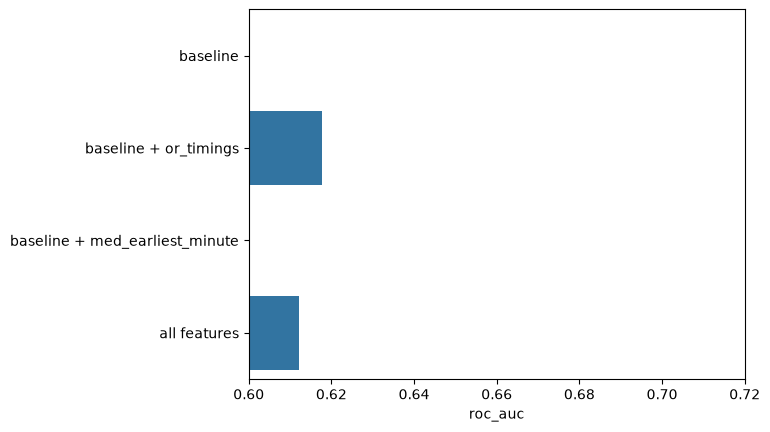

In [40]:
tmp1 = all_metrics[all_metrics['test'] == 'pcornet_has_med']
tmp1['test'] = 'baseline'

tmp2 = all_metrics[all_metrics['test'] == 'pcornet_has_med + or_timings']
tmp2['test'] = 'baseline + or_timings'

tmp3 = all_metrics[all_metrics['test'] == 'pcornet_has_med + med_earliest_minute']
tmp3['test'] = 'baseline + med_earliest_minute'

tmp4 = all_metrics[all_metrics['test'] == 'pcornet_has_med + med_earliest_minute + or_timings']
tmp4['test'] = 'all features'

tmp = pd.concat([tmp1, tmp2, tmp3, tmp4], axis=0)
tmp.columns.name = ''

sns.barplot(tmp, x='roc_auc', y='test', errorbar=None)
plt.xlim([0.60, 0.72])
plt.ylabel('')

In [41]:
summary[['ap', 'sens_80']]

,ap,sens_80
test,,
pcornet_has_med,0.060105,0.039632
pcornet_has_med + or_timings,0.060708,0.040807
pcornet_has_med + med_earliest_minute,0.059364,0.039379
pcornet_has_med + med_earliest_minute + or_timings,0.059049,0.040835


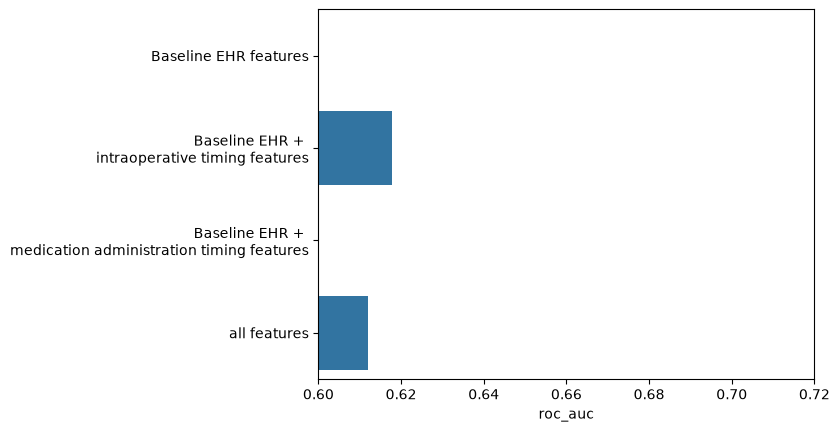

In [42]:
tmp1 = all_metrics[all_metrics['test'] == 'pcornet_has_med']
tmp1['test'] = 'Baseline EHR features'

tmp2 = all_metrics[all_metrics['test'] == 'pcornet_has_med + or_timings']
tmp2['test'] = 'Baseline EHR + \nintraoperative timing features'

tmp3 = all_metrics[all_metrics['test'] == 'pcornet_has_med + med_earliest_minute']
tmp3['test'] = 'Baseline EHR + \nmedication administration timing features'

tmp4 = all_metrics[all_metrics['test'] == 'pcornet_has_med + med_earliest_minute + or_timings']
tmp4['test'] = 'all features'

tmp = pd.concat([tmp1, tmp2, tmp3, tmp4], axis=0)
tmp.columns.name = ''

sns.barplot(tmp, x='roc_auc', y='test', errorbar=None)
plt.xlim([0.60, 0.72])
plt.ylabel('')
plt.savefig(results_dir / 'figure_2.png', bbox_inches='tight', dpi=200)